In [1]:
pip install scikit-learn joblib xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 1.6 MB/s eta 0:00:30
    --------------------------------------- 1.0/48.9 MB 1.7 MB/s eta 0:00:28
   - -------------------------------------- 1.6/48.9 MB 1.7 MB/s eta 0:00:28
   - -------------------------------------- 1.8/48.9 MB 1.8 MB/s eta 0:00:27
   - -------------------------------------- 2.1/48.9 MB 1.9 MB/s eta 0:00:25
   - -------------------------------------- 2.4/48.9 MB 1.8 MB/s eta 0:00:27
   - -------------------------------------- 2.4/48.9 MB 1.8 MB/s eta 0:00:27
   - ------------------------------------

In [2]:
import sklearn
import xgboost

print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

scikit-learn: 1.9.0
XGBoost: 3.4.1


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [4]:
df = pd.read_csv(
    "../data/ml/ml_sales_dataset.csv"
)

print(df.shape)

df.head()

(9994, 34)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Weekday,Profit Margin,Sales Category,Order Year,Order Month,Order Day,Order Weekday,Discount Amount,Customer Orders,Product Orders
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Tuesday,16.00,Medium,2016.0,11.0,8.0,1.0,0.000000,3,4
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Tuesday,30.00,High,2016.0,11.0,8.0,1.0,0.000000,3,12
2,3,CA-2016-138688,2016-06-12,NaN,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Sunday,47.00,Low,2016.0,6.0,12.0,6.0,0.000000,5,7
3,4,US-2015-108966,2015-10-11,NaN,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Sunday,-40.00,High,2015.0,10.0,11.0,6.0,430.909875,6,8
4,5,US-2015-108966,2015-10-11,NaN,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Sunday,11.25,Low,2015.0,10.0,11.0,6.0,4.473600,6,5


In [12]:
# Make sure dates are datetime
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Calculate shipping days
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(df[["Order Date", "Ship Date", "Shipping Days"]].head(10))

  Order Date  Ship Date  Shipping Days
0 2016-11-08 2016-11-11            3.0
1 2016-11-08 2016-11-11            3.0
2 2016-06-12        NaT            NaN
3 2015-10-11        NaT            NaN
4 2015-10-11        NaT            NaN
5 2014-06-09        NaT            NaN
6 2014-06-09        NaT            NaN
7 2014-06-09        NaT            NaN
8 2014-06-09        NaT            NaN
9 2014-06-09        NaT            NaN


In [13]:
features = [
    "Quantity",
    "Discount",
    "Shipping Days",
    "Order Year",
    "Order Month",
    "Order Weekday",
    "Category",
    "Sub-Category",
    "Region",
    "Segment"
]

In [14]:
X = df[features]

y = df["Sales"]

In [15]:
numeric_features = [
    "Quantity",
    "Discount",
    "Shipping Days",
    "Order Year",
    "Order Month",
    "Order Weekday"
]

categorical_features = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment"
]

In [16]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [17]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

Train/Test Split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [20]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 7995
Testing rows: 1999


In [21]:
linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)

In [22]:
linear_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Quantity','Discount','Shipping Days',...,'Sub-Category','Region', 'Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

In [23]:
linear_predictions = linear_model.predict(
    X_test
)

Evaluate Linear Regression

In [24]:
def evaluate_model(
    model_name,
    y_true,
    predictions
):
    mae = mean_absolute_error(
        y_true,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            predictions
        )
    )

    r2 = r2_score(
        y_true,
        predictions
    )

    print(f"\n{model_name}")
    print("-" * 40)
    print(f"MAE  : {mae:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R²   : {r2:.4f}")

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [25]:
linear_result = evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)


Linear Regression
----------------------------------------
MAE  : 226.78
RMSE : 693.50
R²   : 0.1858


Model 2 — Decision Tree

In [27]:
tree_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            DecisionTreeRegressor(
                random_state=42,
                max_depth=10
            )
        )
    ]
)

In [28]:
tree_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Quantity','Discount','Shipping Days',...,'Sub-Category','Region', 'Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

In [29]:
tree_predictions = tree_model.predict(
    X_test
)

In [30]:
tree_result = evaluate_model(
    "Decision Tree",
    y_test,
    tree_predictions
)


Decision Tree
----------------------------------------
MAE  : 201.35
RMSE : 716.95
R²   : 0.1298


Model 3 — Random Forest

In [31]:
rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=15,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [32]:
rf_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Quantity','Discount','Shipping Days',...,'Sub-Category','Region', 'Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

In [33]:
rf_predictions = rf_model.predict(
    X_test
)

In [34]:
rf_result = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions
)


Random Forest
----------------------------------------
MAE  : 210.58
RMSE : 709.33
R²   : 0.1482


Model 4 — Gradient Boosting

In [35]:
gb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

In [36]:
gb_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Quantity','Discount','Shipping Days',...,'Sub-Category','Region', 'Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

In [37]:
gb_predictions = gb_model.predict(
    X_test
)

In [38]:
gb_result = evaluate_model(
    "Gradient Boosting",
    y_test,
    gb_predictions
)


Gradient Boosting
----------------------------------------
MAE  : 198.10
RMSE : 685.21
R²   : 0.2052


Compare All Models

In [39]:
results = pd.DataFrame([
    linear_result,
    tree_result,
    rf_result,
    gb_result
])

results

,Model,MAE,RMSE,R2
0,Linear Regression,226.779252,693.502403,0.185803
1,Decision Tree,201.348981,716.949661,0.129816
2,Random Forest,210.576992,709.330468,0.148213
3,Gradient Boosting,198.101465,685.211166,0.205155


In [40]:
results.sort_values(
    "RMSE"
)

,Model,MAE,RMSE,R2
3,Gradient Boosting,198.101465,685.211166,0.205155
0,Linear Regression,226.779252,693.502403,0.185803
2,Random Forest,210.576992,709.330468,0.148213
1,Decision Tree,201.348981,716.949661,0.129816


In [41]:
results.sort_values(
    "R2",
    ascending=False
)

,Model,MAE,RMSE,R2
3,Gradient Boosting,198.101465,685.211166,0.205155
0,Linear Regression,226.779252,693.502403,0.185803
2,Random Forest,210.576992,709.330468,0.148213
1,Decision Tree,201.348981,716.949661,0.129816


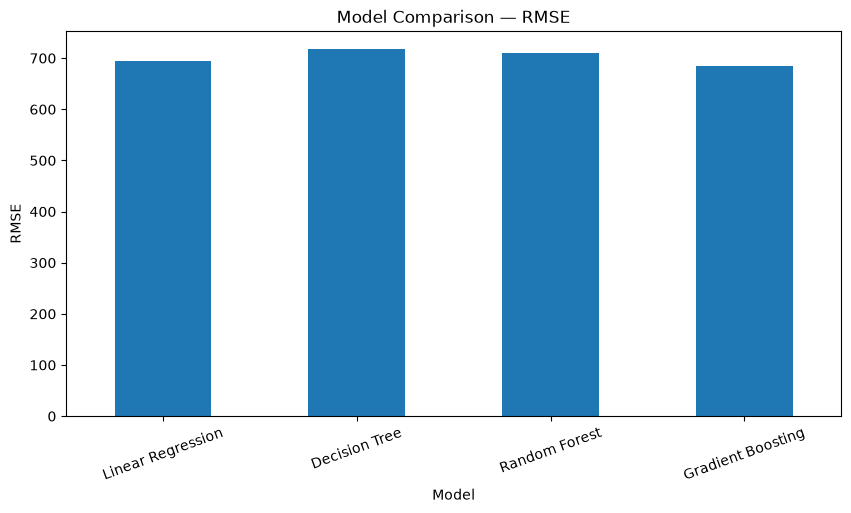

In [42]:
results.plot(
    x="Model",
    y="RMSE",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Model Comparison — RMSE")
plt.ylabel("RMSE")
plt.xlabel("Model")

plt.xticks(rotation=20)

plt.show()

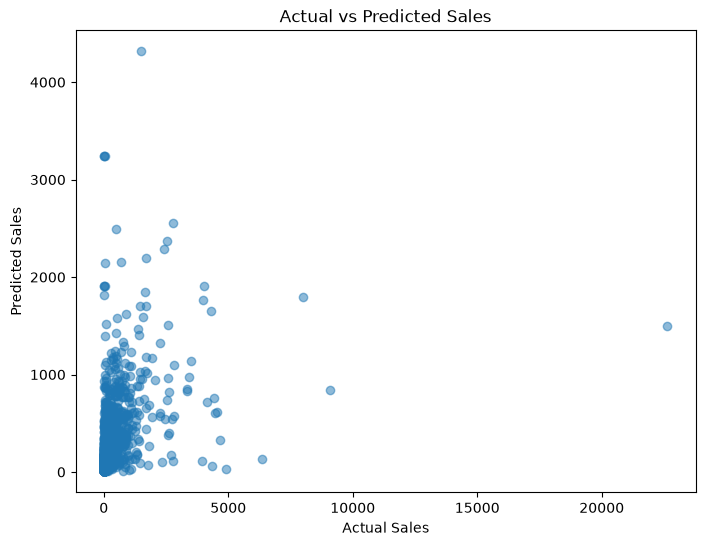

In [43]:
best_predictions = rf_predictions

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.title(
    "Actual vs Predicted Sales"
)

plt.show()

Residual Analysis

In [44]:
residuals = (
    y_test - best_predictions
)

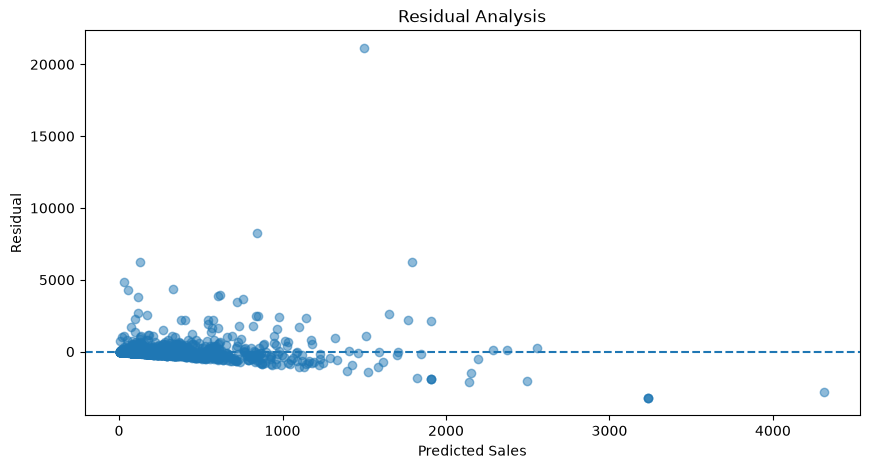

In [45]:
plt.figure(figsize=(10, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Sales")
plt.ylabel("Residual")

plt.title("Residual Analysis")

plt.show()

Cross-Validation

In [46]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [47]:
cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=kf,
    scoring="neg_root_mean_squared_error"
)

In [48]:
cv_rmse = -cv_scores

In [49]:
print("Fold RMSE:", cv_rmse)

print(
    "Mean RMSE:",
    cv_rmse.mean()
)

print(
    "Std RMSE:",
    cv_rmse.std()
)

Fold RMSE: [702.90798355 646.91486315 577.61882871 459.4149979  509.70554529]
Mean RMSE: 579.312443718069
Std RMSE: 88.3960754054252


Hyperparameter Tuning

In [50]:
n_estimators=200
max_depth=15

In [51]:
param_grid = {
    "model__n_estimators": [
        100,
        200
    ],
    "model__max_depth": [
        10,
        15,
        20
    ],
    "model__min_samples_split": [
        2,
        5
    ]
}

In [52]:
grid_search = GridSearchCV(
    rf_model,
    param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

In [53]:
grid_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [10, 15, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True


In [54]:
print(
    grid_search.best_params_
)

{'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 100}


In [55]:
print(
    -grid_search.best_score_
)

508.0252749500592


In [56]:
tuned_rf = grid_search.best_estimator_

tuned_predictions = tuned_rf.predict(
    X_test
)

In [57]:
tuned_result = evaluate_model(
    "Tuned Random Forest",
    y_test,
    tuned_predictions
)


Tuned Random Forest
----------------------------------------
MAE  : 195.78
RMSE : 685.70
R²   : 0.2040


In [58]:
results = pd.concat(
    [
        results,
        pd.DataFrame([tuned_result])
    ],
    ignore_index=True
)

results.sort_values("RMSE")

,Model,MAE,RMSE,R2
3,Gradient Boosting,198.101465,685.211166,0.205155
4,Tuned Random Forest,195.777368,685.701058,0.204018
0,Linear Regression,226.779252,693.502403,0.185803
2,Random Forest,210.576992,709.330468,0.148213
1,Decision Tree,201.348981,716.949661,0.129816


In [59]:
results = pd.concat(
    [
        results,
        pd.DataFrame([tuned_result])
    ],
    ignore_index=True
)

results.sort_values("RMSE")

,Model,MAE,RMSE,R2
3,Gradient Boosting,198.101465,685.211166,0.205155
4,Tuned Random Forest,195.777368,685.701058,0.204018
5,Tuned Random Forest,195.777368,685.701058,0.204018
0,Linear Regression,226.779252,693.502403,0.185803
2,Random Forest,210.576992,709.330468,0.148213
1,Decision Tree,201.348981,716.949661,0.129816


In [60]:
fitted_preprocessor = (
    tuned_rf.named_steps["preprocessor"]
)

In [61]:
feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

In [62]:
rf_estimator = (
    tuned_rf.named_steps["model"]
)

In [63]:
importance = (
    rf_estimator.feature_importances_
)

In [64]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

In [65]:
feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

In [66]:
feature_importance.head(15)

,Feature,Importance
0,num__Quantity,0.197957
15,cat__Sub-Category_Copiers,0.157157
2,num__Shipping Days,0.143116
1,num__Discount,0.075979
20,cat__Sub-Category_Machines,0.058878
7,cat__Category_Office Supplies,0.050608
4,num__Order Month,0.037461
18,cat__Sub-Category_Furnishings,0.036686
5,num__Order Weekday,0.032602
30,cat__Segment_Consumer,0.023950


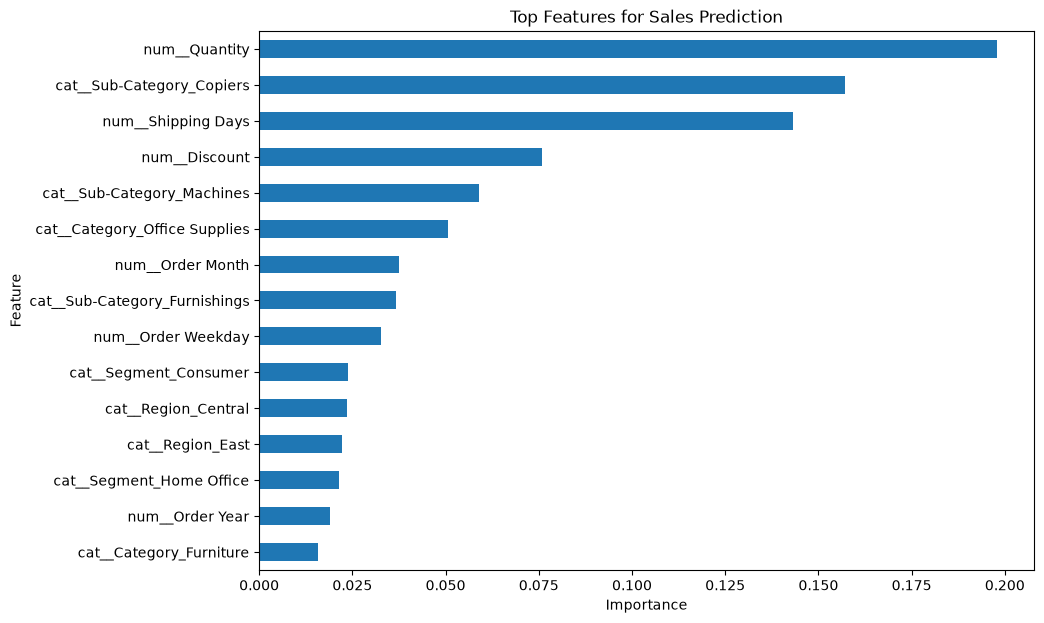

In [67]:
top_features = (
    feature_importance
    .head(15)
    .sort_values("Importance")
)

top_features.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 7),
    legend=False
)

plt.title(
    "Top Features for Sales Prediction"
)

plt.xlabel("Importance")

plt.show()

In [69]:
import os

os.makedirs(
    "../models",
    exist_ok=True
)

In [70]:
joblib.dump(
    tuned_rf,
    "../models/sales_prediction_model.pkl"
)

['../models/sales_prediction_model.pkl']

In [71]:
print(
    "Model saved successfully!"
)

Model saved successfully!


In [72]:
loaded_model = joblib.load(
    "../models/sales_prediction_model.pkl"
)

In [73]:
test_predictions = loaded_model.predict(
    X_test.head(5)
)

print(test_predictions)

[246.54164835  95.37469012  48.50578854 399.76987288 459.78787258]
